In [1]:
import os
import sys
from datetime import date, datetime

# import torch
# from torch.func import jacrev
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import plotly.express as px
import polars as pl
import pytz

project_root = os.path.abspath("/Users/elie/Documents/GitHub/quant_data/")

if project_root not in sys.path:
    sys.path.insert(0, project_root)


os.environ["QUANTDATA_RAW_DATA"] = "!/quantdata/raw"  # better set these to environment variables
os.environ["QUANTDATA_TRAINING_DATA"] = (
    "!/quantdata/training"  # better set these to environment variables
)
os.environ["QUANTDATA_PROCESSING_DATA"] = (
    "!/quantdata/processing"  # better set these to environment variables
)
os.environ["QUANTDATA_CACHE_MODE"] = "on"  # turns off global cache mode
os.environ["QUANTDATA_TEST_MODE"] = "0"
import importlib as imp

import quantdata as _

imp.reload(_)
import quantdata.biz_calendar as _

imp.reload(_)
import quantdata.massive.client as _

imp.reload(_)
import quantdata.massive.options.contracts as _

imp.reload(_)

from datetime import date

import arbitrage
import black_scholes
import ekf
import events
import kalman_filters
import plots
import utils
from cdxcore.util import fmt_date, fmt_dict
from cdxcore.verbose import Context

from quantdata.massive.client import MassiveClient
from quantdata.massive.taq import TAQMatchConfig, match_taq

/Users/elie/Documents/GitHub/quant_data/quantdata/__init__.py:152: UserWarning: Using cache mode 'on' as specified in environment variable QUANTDATA_CACHE_MODE.


In [2]:
df_tickers = pl.read_csv("spy_options_tickers.csv")

In [3]:
df_tickers["ticker"][0]

'O:SPY240105C00270000'

In [4]:
option_ticker = df_tickers["ticker"][0]
client = MassiveClient()
df_quotes = client.fetch_quotes(option_ticker, date(2024, 1, 3))
df_trades = client.fetch_trades(option_ticker, date(2024, 1, 3))

In [5]:
df_spy = client.fetch_trades("SPY", date(2024, 1, 3))

In [6]:
df_matched = match_taq(option_ticker, date(2024, 1, 3))

In [7]:
strike, expiry, option_type = utils.parse_option_ticker(option_ticker)

df_trades_result, df_iv_trades_result, df_quotes_result, df_iv_quotes_result = (
    kalman_filters.kalman_filter_from_matched(
        df_quotes=df_quotes,
        df_matched=df_matched,
        df_spy=df_spy,
        strike=strike,
        expiry=expiry,
        option_type=option_type,
    )
)

In [8]:
# r2_price = utils.r_squared(df_trades_result["observed_price"], df_trades_result["trade_residual"])
# r2_iv = utils.r_squared(df_iv_trades_result["observed_iv"], df_iv_trades_result["trade_residual"])

# print(f"R² (price space): {r2_price:.4f}")
# print(f"R² (IV space):    {r2_iv:.4f}")

## IV Volatility Surface — all strikes

In [9]:
imp.reload(kalman_filters)
imp.reload(utils)

<module 'utils' from '/Users/elie/Documents/GitHub/quant_data/personal/personal_notebooks/utils.py'>

In [10]:
df_tickers

ticker,trade_count,ticker_suffix
str,i64,f64
"""O:SPY240105C00270000""",1,270000.0
"""O:SPY240105C00375000""",1,375000.0
"""O:SPY240105C00376000""",6,376000.0
"""O:SPY240105C00378000""",1,378000.0
"""O:SPY240105C00379000""",6,379000.0
…,…,…
"""O:SPY240105P00483000""",3,483000.0
"""O:SPY240105P00485000""",20,485000.0
"""O:SPY240105P00490000""",4,490000.0


In [11]:
# Build IV surface: runs the Kalman filter for every liquid option on the day.
# df_spy is reused from above (already fetched). min_trades filters out
# strikes with no real activity — raise it to keep only the most liquid ones.
trade_date = date(2024, 1, 3)

df_iv_surface_long = kalman_filters.build_iv_surface(
    df_tickers=df_tickers,
    trade_date=trade_date,
    df_spy=df_spy,
    min_trades=100,
)
df_iv_surface_long

O:SPY240105C00469000: dropping 2 bad quotes (crossed×2 (first=2024-01-03 11:49:45.633413-05:00))
O:SPY240105C00472000: dropping 1 bad quotes (crossed×1 (first=2024-01-03 15:51:02.275318-05:00))
O:SPY240105C00473000: dropping 1 bad quotes (crossed×1 (first=2024-01-03 10:29:17.744517-05:00))
O:SPY240105C00474000: dropping 4 bad quotes (crossed×4 (first=2024-01-03 10:25:56.925706-05:00))
O:SPY240105C00475000: dropping 1 bad quotes (crossed×1 (first=2024-01-03 14:02:06.496803-05:00))
O:SPY240105C00477000: dropping 1 bad quotes (crossed×1 (first=2024-01-03 10:00:44.569057-05:00))
Skipping O:SPY240105C00481000: 46 bad quotes (sub-tick bid×46)
Skipping O:SPY240105C00482000: 64 bad quotes (sub-tick bid×64)
Skipping O:SPY240105C00483000: 842 bad quotes (sub-tick bid×842, zero bid size×1)
Skipping O:SPY240105C00484000: 2129 bad quotes (sub-tick bid×2129, zero bid size×1)
Skipping O:SPY240105C00485000: 3888 bad quotes (sub-tick bid×3888, zero bid size×2)


ts_ns,bid_iv,ask_iv,kalman_iv,strike
"datetime[ns, America/New_York]",f64,f64,f64,f64
2024-01-03 09:30:00.006781440 EST,0.134075,0.139497,0.13695,479.0
2024-01-03 09:30:00.008340992 EST,0.131123,0.144509,0.137211,479.0
2024-01-03 09:30:00.008425216 EST,0.132129,0.144187,0.138423,477.0
2024-01-03 09:30:00.008425216 EST,0.131226,0.143125,0.137421,478.0
2024-01-03 09:30:00.008941568 EST,0.15832,0.16274,0.160533,468.0
…,…,…,…,…
2024-01-03 16:14:55.718364928 EST,0.142977,0.143724,0.143358,470.0
2024-01-03 16:14:55.721362176 EST,0.145399,0.146125,0.145878,469.0
2024-01-03 16:14:57.942319616 EST,0.1454,0.146126,0.145764,469.0


In [12]:
# Synchronize: forward-fill each strike's IV onto the merged timestamp spine.
# Result is wide: one row per tick, columns bid_iv_402 / ask_iv_402 / kalman_iv_402 etc.
df_iv_surface_wide = utils.synchronize_iv_surface(df_iv_surface_long)
df_iv_surface_wide

ts_ns,bid_iv_454,ask_iv_454,kalman_iv_454,bid_iv_465,ask_iv_465,kalman_iv_465,bid_iv_466,ask_iv_466,kalman_iv_466,bid_iv_467,ask_iv_467,kalman_iv_467,bid_iv_468,ask_iv_468,kalman_iv_468,bid_iv_469,ask_iv_469,kalman_iv_469,bid_iv_470,ask_iv_470,kalman_iv_470,bid_iv_471,ask_iv_471,kalman_iv_471,bid_iv_472,ask_iv_472,kalman_iv_472,bid_iv_473,ask_iv_473,kalman_iv_473,bid_iv_474,ask_iv_474,kalman_iv_474,bid_iv_475,ask_iv_475,kalman_iv_475,bid_iv_476,ask_iv_476,kalman_iv_476,bid_iv_477,ask_iv_477,kalman_iv_477,bid_iv_478,ask_iv_478,kalman_iv_478,bid_iv_479,ask_iv_479,kalman_iv_479,bid_iv_480,ask_iv_480,kalman_iv_480
"datetime[ns, America/New_York]",f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2024-01-03 09:30:00.006781440 EST,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.134075,0.139497,0.13695,null,null,null
2024-01-03 09:30:00.008340992 EST,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.131123,0.144509,0.137211,null,null,null
2024-01-03 09:30:00.008425216 EST,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.132129,0.144187,0.138423,0.131226,0.143125,0.137421,0.131123,0.144509,0.137211,null,null,null
2024-01-03 09:30:00.008941568 EST,null,null,null,null,null,null,null,null,null,null,null,null,0.15832,0.16274,0.160533,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.132129,0.144187,0.138423,0.131226,0.143125,0.137421,0.131123,0.144509,0.137211,null,null,null
2024-01-03 09:30:00.031845888 EST,null,null,null,null,null,null,null,null,null,null,null,null,0.15832,0.16274,0.160533,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.132129,0.144187,0.138423,0.131226,0.143125,0.137421,0.130745,0.1441,0.137318,null,null,null
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2024-01-03 16:14:55.718364928 EST,0.237893,0.337047,0.287928,0.158446,0.167526,0.162557,0.155239,0.159367,0.157135,0.152155,0.153688,0.152904,0.148558,0.149291,0.148924,0.145399,0.14685,0.145857,0.142977,0.143724,0.143358,0.140561,0.142169,0.141123,0.140052,0.140954,0.140748,0.138843,0.140961,0.139345,0.137698,0.139007,0.138864,0.136742,0.138443,0.137708,0.136156,0.138492,0.137098,0.133145,0.136459,0.135365,0.132898,0.13777,0.135411,0.131346,0.138717,0.136687,0.141856,0.150118,0.142304
2024-01-03 16:14:55.721362176 EST,0.237893,0.337047,0.287928,0.158446,0.167526,0.162557,0.155239,0.159367,0.157135,0.152155,0.153688,0.152904,0.148558,0.149291,0.148924,0.145399,0.146125,0.145878,0.142977,0.143724,0.143358,0.140561,0.142169,0.141123,0.140052,0.140954,0.140748,0.138843,0.140961,0.139345,0.137698,0.139007,0.138864,0.136742,0.138443,0.137708,0.136156,0.138492,0.137098,0.133145,0.136459,0.135365,0.132898,0.13777,0.135411,0.131346,0.138717,0.136687,0.141856,0.150118,0.142304
2024-01-03 16:14:57.942319616 EST,0.237893,0.337047,0.287928,0.158446,0.167526,0.162557,0.155239,0.159367,0.157135,0.152155,0.153688,0.152904,0.148558,0.149291,0.148924,0.1454,0.146126,0.145764,0.142977,0.143724,0.143358,0.140561,0.142169,0.141123,0.140052,0.140954,0.140748,0.138843,0.140961,0.139345,0.137698,0.139007,0.138864,0.136742,0.138443,0.137708,0.136156,0.138492,0.137098,0.133145,0.136459,0.135365,0.132898,0.13777,0.135411,0.131346,0.138717,0.136687,0

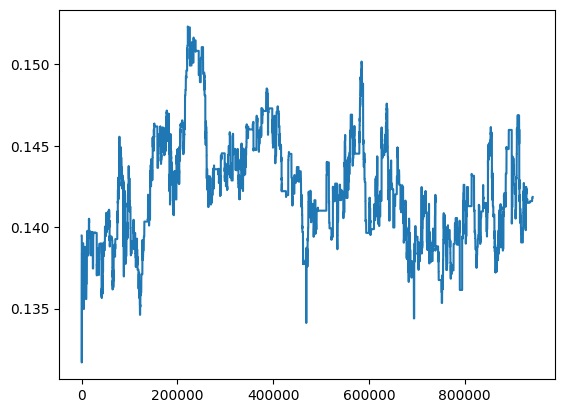

In [13]:
plt.plot(df_iv_surface_wide.select(pl.col("bid_iv_480")))

In [14]:
df_iv_surface_wide.shape

(942230, 52)

In [15]:
df_iv_surface_wide.select(pl.col("bid_iv_480").is_null()).sum()

bid_iv_480
u32
8


In [16]:
df_iv_surface_wide.select(pl.col("bid_iv_480").is_nan()).sum()

bid_iv_480
u32
0


In [17]:
import polars.selectors as cs

df_iv_surface_wide.select(
    pl.all().is_null().sum().name.suffix("_nulls"),
    cs.float().is_nan().sum().name.suffix("_nans"),
)

ts_ns_nulls,bid_iv_454_nulls,ask_iv_454_nulls,kalman_iv_454_nulls,bid_iv_465_nulls,ask_iv_465_nulls,kalman_iv_465_nulls,bid_iv_466_nulls,ask_iv_466_nulls,kalman_iv_466_nulls,bid_iv_467_nulls,ask_iv_467_nulls,kalman_iv_467_nulls,bid_iv_468_nulls,ask_iv_468_nulls,kalman_iv_468_nulls,bid_iv_469_nulls,ask_iv_469_nulls,kalman_iv_469_nulls,bid_iv_470_nulls,ask_iv_470_nulls,kalman_iv_470_nulls,bid_iv_471_nulls,ask_iv_471_nulls,kalman_iv_471_nulls,bid_iv_472_nulls,ask_iv_472_nulls,kalman_iv_472_nulls,bid_iv_473_nulls,ask_iv_473_nulls,kalman_iv_473_nulls,bid_iv_474_nulls,ask_iv_474_nulls,kalman_iv_474_nulls,bid_iv_475_nulls,ask_iv_475_nulls,kalman_iv_475_nulls,…,kalman_iv_468_nans,bid_iv_469_nans,ask_iv_469_nans,kalman_iv_469_nans,bid_iv_470_nans,ask_iv_470_nans,kalman_iv_470_nans,bid_iv_471_nans,ask_iv_471_nans,kalman_iv_471_nans,bid_iv_472_nans,ask_iv_472_nans,kalman_iv_472_nans,bid_iv_473_nans,ask_iv_473_nans,kalman_iv_473_nans,bid_iv_474_nans,ask_iv_474_nans,kalman_iv_474_nans,bid_iv_475_nans,ask_iv_475_nans,kalman_iv_475_nans,bid_iv_476_nans,ask_iv_476_nans,kalman_iv_476_nans,bid_iv_477_nans,ask_iv_477_nans,kalman_iv_477_nans,bid_iv_478_nans,ask_iv_478_nans,kalman_iv_478_nans,bid_iv_479_nans,ask_iv_479_nans,kalman_iv_479_nans,bid_iv_480_nans,ask_iv_480_nans,kalman_iv_480_nans
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,…,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,29,29,29,24,24,24,22,22,22,39,39,39,3,3,3,23,23,23,15,15,15,17,17,17,5,5,5,16,16,16,12,12,12,11,11,11,…,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [18]:
# df_iv_surface_wide.select(pl.col("kalman_iv_469").is_nan())

In [19]:
import polars.selectors as cs

df_filtered = df_iv_surface_wide.filter(
    pl.all_horizontal(pl.all().is_not_null()) & pl.all_horizontal(cs.float().is_not_nan())
)

In [20]:
snapshot_ts = df_iv_surface_wide["ts_ns"].median()  # mid-day snapshot

In [21]:
snapshot_ts

datetime.datetime(2024, 1, 3, 13, 2, 6, 14486, tzinfo=zoneinfo.ZoneInfo(key='America/New_York'))

In [22]:
# Snapshot: pick a moment in time and plot the IV smile across strikes.
# join_asof gives the last known IV for each strike at that timestamp.
# snapshot_ts = df_iv_surface_wide["ts_ns"].median()  # mid-day snapshot

snapshot_ts = df_iv_surface_wide.filter(
    pl.all_horizontal(pl.all().is_not_null()) & pl.all_horizontal(cs.float().is_not_nan())
)["ts_ns"][100]


row = df_iv_surface_wide.filter(pl.col("ts_ns") <= snapshot_ts).tail(1)
strikes_in_surface = sorted(df_iv_surface_long["strike"].unique().to_list())

mid_ivs = [row[f"kalman_iv_{int(k)}"][0] for k in strikes_in_surface]
bid_ivs = [row[f"bid_iv_{int(k)}"][0] for k in strikes_in_surface]
ask_ivs = [row[f"ask_iv_{int(k)}"][0] for k in strikes_in_surface]

import plotly.graph_objects as go

fig = go.Figure()
fig.add_trace(
    go.Scatter(x=strikes_in_surface, y=mid_ivs, mode="lines+markers", name="kalman mid IV")
)
fig.add_trace(
    go.Scatter(x=strikes_in_surface, y=bid_ivs, mode="lines", name="bid IV", line=dict(dash="dot"))
)
fig.add_trace(
    go.Scatter(x=strikes_in_surface, y=ask_ivs, mode="lines", name="ask IV", line=dict(dash="dot"))
)
fig.update_layout(
    title=f"IV smile — {snapshot_ts}", xaxis_title="Strike", yaxis_title="Implied Vol"
)
fig.show()

In [23]:
tte = (expiry - snapshot_ts).total_seconds() / (365.25 * 24 * 3600)

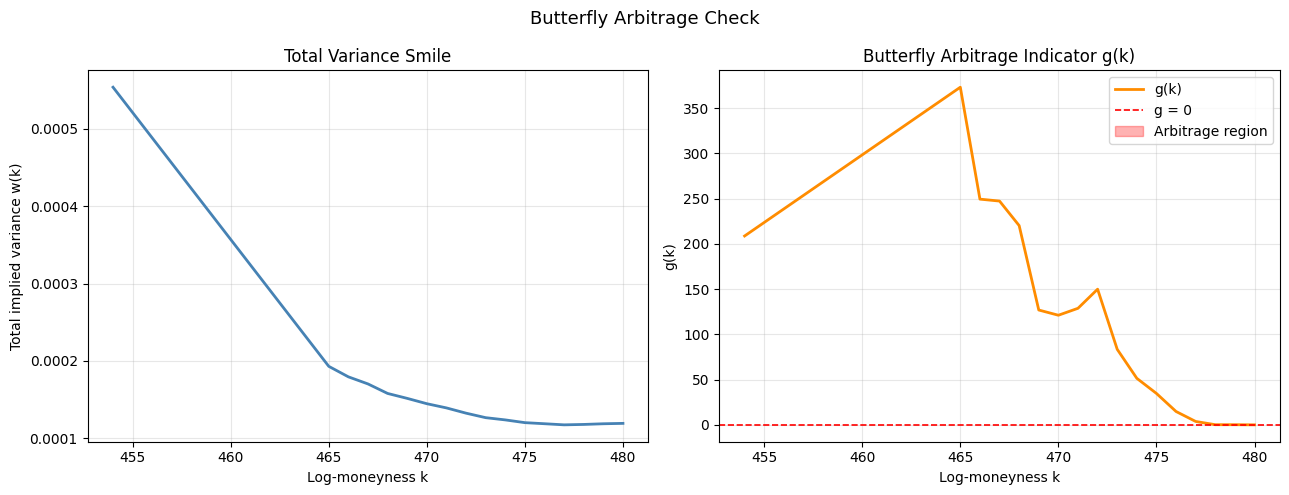

{'is_arbitrage_free': True,
 'min_g': 0.0004152555517116481,
 'violations': array([], dtype=float64),
 'g': array([2.08681939e+02, 3.73078711e+02, 2.49400323e+02, 2.47262585e+02,
        2.20175437e+02, 1.26879460e+02, 1.21110617e+02, 1.28788008e+02,
        1.49902110e+02, 8.34595323e+01, 5.14010774e+01, 3.47065215e+01,
        1.47517285e+01, 3.73919396e+00, 1.69054609e-01, 1.54107263e-01,
        4.15255552e-04]),
 'w': array([0.00055373, 0.00019294, 0.00017934, 0.00017017, 0.00015788,
        0.0001515 , 0.00014462, 0.00013918, 0.00013239, 0.00012657,
        0.00012368, 0.00012013, 0.00011873, 0.0001173 , 0.00011781,
        0.00011869, 0.00011919]),
 'k': array([454., 465., 466., 467., 468., 469., 470., 471., 472., 473., 474.,
        475., 476., 477., 478., 479., 480.]),
 'lee_bound_ok': True}

In [24]:
arbitrage.check_butterfly(k=strikes_in_surface, iv=mid_ivs, T=tte, plot=True)

In [25]:
expiry

datetime.datetime(2024, 1, 5, 16, 0, tzinfo=<DstTzInfo 'America/New_York' LMT-1 day, 19:04:00 STD>)

In [26]:
(expiry - row["ts_ns"]).dt.total_seconds() / (365.25 * 24 * 3600)

ts_ns
f64
0.00621


In [27]:
df_filtered[0]["ts_ns"]

ts_ns
"datetime[ns, America/New_York]"
2024-01-03 09:30:00.232904704 EST


In [28]:
for i in range(0, df_filtered.shape[0], 100):
    row = df_filtered[i]
    strikes_in_surface = sorted(df_iv_surface_long["strike"].unique().to_list())
    mid_ivs = [row[f"kalman_iv_{int(k)}"][0] for k in strikes_in_surface]
    bid_ivs = [row[f"bid_iv_{int(k)}"][0] for k in strikes_in_surface]
    ask_ivs = [row[f"ask_iv_{int(k)}"][0] for k in strikes_in_surface]
    tte = float((expiry - row["ts_ns"])[0].total_seconds()) / (365.25 * 24 * 3600)
    if not (
        arbitrage.check_butterfly(k=strikes_in_surface, iv=mid_ivs, T=tte, plot=False)[
            "is_arbitrage_free"
        ]
    ):
        print(f"Arbitrage detected at index {i} (timestamp {row['ts_ns'][0]})")

## IV Volatility Surface — puts

In [29]:
imp.reload(black_scholes)
imp.reload(events)
imp.reload(ekf)
imp.reload(kalman_filters)
imp.reload(utils)

<module 'utils' from '/Users/elie/Documents/GitHub/quant_data/personal/personal_notebooks/utils.py'>

In [30]:
df_iv_surface_long_puts = kalman_filters.build_iv_surface(
    df_tickers=df_tickers,
    trade_date=trade_date,
    df_spy=df_spy,
    min_trades=100,
    option_type="P",
)
df_iv_surface_long_puts

O:SPY240105P00450000: dropping 1 bad quotes (sub-tick bid×1 (first=2024-01-03 09:30:00.141481-05:00))
O:SPY240105P00459000: dropping 8 bad quotes (sub-tick bid×8 (first=2024-01-03 13:59:58.839405-05:00))
O:SPY240105P00462000: dropping 1 bad quotes (crossed×1 (first=2024-01-03 15:50:08.374645-05:00))
Skipping O:SPY240105P00462500: 17 bad quotes (sub-tick bid×17)
O:SPY240105P00463000: dropping 2 bad quotes (crossed×2 (first=2024-01-03 14:11:33.204992-05:00))
O:SPY240105P00464000: dropping 3 bad quotes (crossed×3 (first=2024-01-03 14:00:35.566504-05:00))
O:SPY240105P00465000: dropping 2 bad quotes (crossed×2 (first=2024-01-03 10:10:21.536791-05:00))
O:SPY240105P00466000: dropping 2 bad quotes (crossed×2 (first=2024-01-03 10:02:08.195802-05:00))
O:SPY240105P00467000: dropping 3 bad quotes (crossed×3 (first=2024-01-03 09:59:29.027314-05:00))
O:SPY240105P00468000: dropping 1 bad quotes (crossed×1 (first=2024-01-03 13:33:20.763030-05:00))
O:SPY240105P00469000: dropping 1 bad quotes (crossed×1

ts_ns,bid_iv,ask_iv,kalman_iv,strike
"datetime[ns, America/New_York]",f64,f64,f64,f64
2024-01-03 09:30:00.008294144 EST,0.126371,0.129092,0.127732,471.0
2024-01-03 09:30:00.008504576 EST,0.140865,0.142848,0.141883,466.0
2024-01-03 09:30:00.008594688 EST,0.143565,0.145845,0.14471,465.0
2024-01-03 09:30:00.008800256 EST,0.145223,0.159941,0.152948,462.0
2024-01-03 09:30:00.008815872 EST,0.143385,0.15533,0.149568,463.0
…,…,…,…,…
2024-01-03 16:14:56.120656640 EST,0.074329,0.102374,0.094279,474.0
2024-01-03 16:14:59.884593152 EST,0.07433,0.104474,0.093966,474.0
2024-01-03 16:14:59.884598272 EST,0.108205,0.114425,0.110651,472.0


In [31]:
df_iv_surface_wide_puts = utils.synchronize_iv_surface(df_iv_surface_long_puts)
df_iv_surface_wide_puts

ts_ns,bid_iv_450,ask_iv_450,kalman_iv_450,bid_iv_458,ask_iv_458,kalman_iv_458,bid_iv_459,ask_iv_459,kalman_iv_459,bid_iv_460,ask_iv_460,kalman_iv_460,bid_iv_461,ask_iv_461,kalman_iv_461,bid_iv_462,ask_iv_462,kalman_iv_462,bid_iv_463,ask_iv_463,kalman_iv_463,bid_iv_464,ask_iv_464,kalman_iv_464,bid_iv_465,ask_iv_465,kalman_iv_465,bid_iv_466,ask_iv_466,kalman_iv_466,bid_iv_467,ask_iv_467,kalman_iv_467,bid_iv_468,ask_iv_468,kalman_iv_468,bid_iv_469,ask_iv_469,kalman_iv_469,bid_iv_470,ask_iv_470,kalman_iv_470,bid_iv_471,ask_iv_471,kalman_iv_471,bid_iv_472,ask_iv_472,kalman_iv_472,bid_iv_473,ask_iv_473,kalman_iv_473,bid_iv_474,ask_iv_474,kalman_iv_474,bid_iv_475,ask_iv_475,kalman_iv_475,bid_iv_476,ask_iv_476,kalman_iv_476,bid_iv_477,ask_iv_477,kalman_iv_477
"datetime[ns, America/New_York]",f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2024-01-03 09:30:00.008294144 EST,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.126371,0.129092,0.127732,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
2024-01-03 09:30:00.008504576 EST,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.140865,0.142848,0.141883,null,null,null,null,null,null,null,null,null,null,null,null,0.126371,0.129092,0.127732,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
2024-01-03 09:30:00.008594688 EST,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.143565,0.145845,0.14471,0.140865,0.142848,0.141883,null,null,null,null,null,null,null,null,null,null,null,null,0.126371,0.129092,0.127732,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
2024-01-03 09:30:00.008800256 EST,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.145223,0.159941,0.152948,null,null,null,null,null,null,0.143565,0.145845,0.14471,0.140865,0.142848,0.141883,null,null,null,null,null,null,null,null,null,null,null,null,0.126371,0.129092,0.127732,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
2024-01-03 09:30:00.008815872 EST,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.145223,0.159941,0.152948,0.143385,0.15533,0.149568,null,null,null,0.143565,0.145845,0.14471,0.140865,0.142848,0.141883,null,null,null,null,null,null,null,null,null,null,null,null,0.126371,0.129092,0.127732,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2024-01-03 16:14:56.120331008 EST,0.228726,0.240509,0.234216,0.159334,0.164152,0.161908,0.155299,0.159174,0.156138,0.148714,0.151785,0.150262,0.145432,0.147828,0.146761,0.140848,0.142754,0.142638,0.137858,0.139363,0.139017,0.135908,0.137118,0.136185,0.133482,0.134489,0.133505,0.130622,0.131495,0.131055,0.128139,0.128923,0.12846,0.125065,0.126537,0.125703,0.122183,0.123635,0.122963,0.118936,0.121209,0.120059,0.115857,0.119228,0.116725,0.108203,0.114424,0.110998,0.094459,0.110675,0.104433,0.074329,0.102374,0.093842,0.01,0.136742,0.082012,0.01,0.152475,0.108758,0.01,0.16784,0.107114
2024-01-03 16:14:56.120656640 EST,0.228726,0.240509,0.234216,0.159334,0.164152,0.161908,0.155299,0.159174,0.156138,0.148714,0.151785,0.150262,0.145432,0.147828,0.146761,0.140848,0.142754,0.142638,0.137858,0.139363,0.139017,0.135908,0.137118,0.136185,0.133482,0.134489,0.133505,0.130622,0.131495,0.131055,0.128139,0.12

In [32]:
df_filtered_puts = df_iv_surface_wide_puts.filter(
    pl.all_horizontal(pl.all().is_not_null()) & pl.all_horizontal(cs.float().is_not_nan())
)
df_filtered_puts

ts_ns,bid_iv_450,ask_iv_450,kalman_iv_450,bid_iv_458,ask_iv_458,kalman_iv_458,bid_iv_459,ask_iv_459,kalman_iv_459,bid_iv_460,ask_iv_460,kalman_iv_460,bid_iv_461,ask_iv_461,kalman_iv_461,bid_iv_462,ask_iv_462,kalman_iv_462,bid_iv_463,ask_iv_463,kalman_iv_463,bid_iv_464,ask_iv_464,kalman_iv_464,bid_iv_465,ask_iv_465,kalman_iv_465,bid_iv_466,ask_iv_466,kalman_iv_466,bid_iv_467,ask_iv_467,kalman_iv_467,bid_iv_468,ask_iv_468,kalman_iv_468,bid_iv_469,ask_iv_469,kalman_iv_469,bid_iv_470,ask_iv_470,kalman_iv_470,bid_iv_471,ask_iv_471,kalman_iv_471,bid_iv_472,ask_iv_472,kalman_iv_472,bid_iv_473,ask_iv_473,kalman_iv_473,bid_iv_474,ask_iv_474,kalman_iv_474,bid_iv_475,ask_iv_475,kalman_iv_475,bid_iv_476,ask_iv_476,kalman_iv_476,bid_iv_477,ask_iv_477,kalman_iv_477
"datetime[ns, America/New_York]",f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2024-01-03 09:30:00.193351168 EST,0.230858,0.251809,0.242527,0.173617,0.178065,0.175897,0.165916,0.173536,0.169411,0.160819,0.166963,0.163651,0.156516,0.159098,0.157883,0.152496,0.154547,0.154141,0.149082,0.150786,0.150646,0.147237,0.148611,0.147927,0.143565,0.145845,0.14471,0.140865,0.142848,0.141883,0.135586,0.144062,0.138499,0.135564,0.138609,0.137088,0.133375,0.13546,0.134476,0.130253,0.132969,0.131611,0.126371,0.129092,0.127732,0.114238,0.133522,0.123922,0.118176,0.122941,0.120566,0.01,0.167056,0.116089,0.01,0.171921,0.112943,0.01,0.190196,0.109668,0.01,0.203651,0.103032
2024-01-03 09:30:00.194728448 EST,0.230858,0.251809,0.242527,0.173617,0.178065,0.175897,0.165916,0.173536,0.169411,0.160819,0.166963,0.163651,0.156516,0.159098,0.157883,0.152496,0.154547,0.154141,0.149082,0.150786,0.150646,0.147237,0.148611,0.147927,0.143565,0.145845,0.14471,0.140865,0.142848,0.141883,0.135586,0.144062,0.138499,0.135564,0.138609,0.137088,0.133375,0.13546,0.134476,0.130253,0.132969,0.131611,0.126371,0.129092,0.127732,0.114238,0.133522,0.123922,0.118176,0.122941,0.120566,0.01,0.167056,0.116089,0.094033,0.129704,0.113096,0.01,0.190196,0.109668,0.01,0.203651,0.103032
2024-01-03 09:30:00.199043840 EST,0.230858,0.251809,0.242527,0.173617,0.178065,0.175897,0.165916,0.173536,0.169411,0.160819,0.166963,0.163651,0.156516,0.159098,0.157883,0.152496,0.154547,0.154141,0.149082,0.150786,0.150646,0.147237,0.148611,0.147927,0.143565,0.145845,0.14471,0.140865,0.142848,0.141883,0.135586,0.144062,0.138499,0.135564,0.138609,0.137088,0.133375,0.13546,0.134476,0.130253,0.132969,0.131611,0.126371,0.129092,0.127732,0.114238,0.133522,0.123922,0.118176,0.122941,0.120566,0.106324,0.111267,0.109983,0.094033,0.129704,0.113096,0.01,0.190196,0.109668,0.01,0.203651,0.103032
2024-01-03 09:30:00.210175232 EST,0.230858,0.251809,0.242527,0.173617,0.178065,0.175897,0.165916,0.173536,0.169411,0.160819,0.166963,0.163651,0.156516,0.159098,0.157883,0.152496,0.154547,0.154141,0.149082,0.150786,0.150646,0.147237,0.148611,0.147927,0.143565,0.145845,0.14471,0.140865,0.142848,0.141883,0.135586,0.144062,0.138499,0.135564,0.138609,0.137088,0.133375,0.13546,0.134476,0.130253,0.132969,0.131611,0.126371,0.129092,0.127732,0.114238,0.133522,0.123922,0.118176,0.122941,0.120566,0.106324,0.111267,0.109983,0.01,0.171921,0.113094,0.01,0.190196,0.109668,0.01,0.203651,0.103032
2024-01-03 09:30:00.214310144 EST,0.230858,0.251809,0.242527,0.173617,0.178065,0.175897,0.165916,0.173536,0.169411,0.160819,0.166963,0.163651,0.156516,0.159098,0.157883,0.152496,0.154547,0.154141,0.149082,0.150786,0.150646,0.147237,0.148611,0.147927,0.143565,0.145845,0.14471,0.140865,0.142848,0.141883,0.135586,0.144062,0.138499,0.135564,0.138609,0.137088,0.133375,0.13546,0.134476,0.130253,0.132969,0.131611,0.126371,0.129092,0.127732,0.123565,0.126419,0.124954,0.118176,0.122941,0.120566,0.106324,0.111267,0.109983,0.01,0.171921,0.113094,0.01,0.190196,0.109668,0.01,0.203651,0.103032
…,…,…,…,…,…,…,…,…,

In [33]:
snapshot_ts_puts = df_filtered_puts["ts_ns"][1000]
row_puts = df_iv_surface_wide_puts.filter(pl.col("ts_ns") <= snapshot_ts_puts).tail(1)
strikes_puts = sorted(df_iv_surface_long_puts["strike"].unique().to_list())
_, expiry_put, _ = utils.parse_option_ticker(
    df_tickers.filter(pl.col("ticker").str.contains("P"))["ticker"][0]
)

mid_ivs_puts = [row_puts[f"kalman_iv_{int(k)}"][0] for k in strikes_puts]
bid_ivs_puts = [row_puts[f"bid_iv_{int(k)}"][0] for k in strikes_puts]
ask_ivs_puts = [row_puts[f"ask_iv_{int(k)}"][0] for k in strikes_puts]

fig = go.Figure()
fig.add_trace(
    go.Scatter(x=strikes_puts, y=mid_ivs_puts, mode="lines+markers", name="kalman mid IV")
)
fig.add_trace(
    go.Scatter(x=strikes_puts, y=bid_ivs_puts, mode="lines", name="bid IV", line=dict(dash="dot"))
)
fig.add_trace(
    go.Scatter(x=strikes_puts, y=ask_ivs_puts, mode="lines", name="ask IV", line=dict(dash="dot"))
)
fig.update_layout(
    title=f"Put IV smile — {snapshot_ts_puts}", xaxis_title="Strike", yaxis_title="Implied Vol"
)
fig.show()

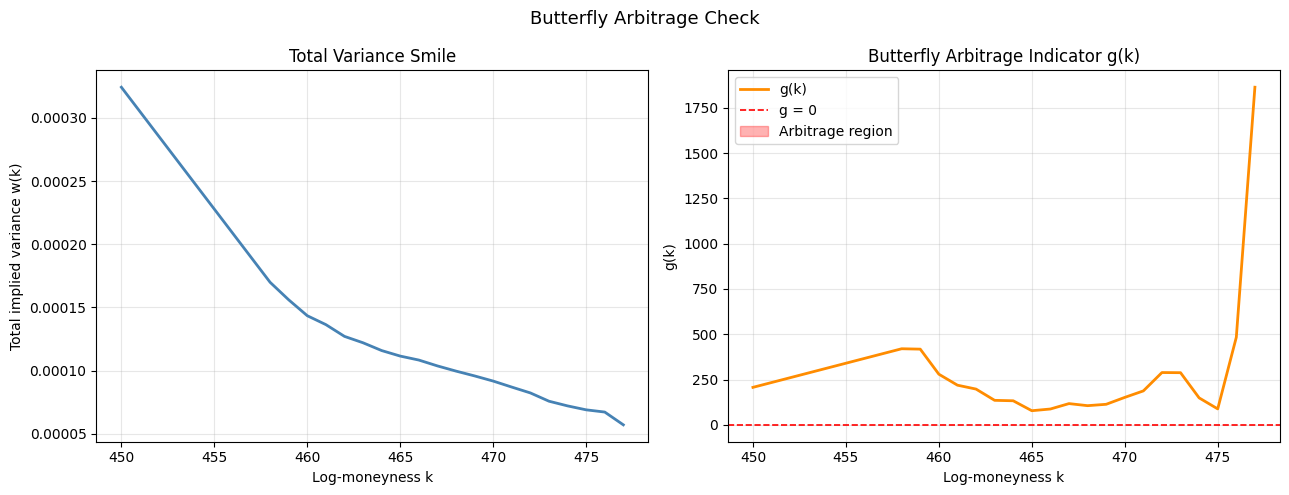

{'is_arbitrage_free': True,
 'min_g': 77.95921131244165,
 'violations': array([], dtype=float64),
 'g': array([ 206.89549296,  419.96937489,  417.81087053,  279.53186934,
         218.90956674,  197.38711993,  135.25182545,  132.81040821,
          77.95921131,   87.3933775 ,  117.2240675 ,  105.81569397,
         113.39830987,  151.47641281,  187.27679927,  288.65015809,
         287.84850954,  148.77377712,   87.99352717,  483.28970426,
        1863.48472341]),
 'w': array([3.24223483e-04, 1.69935041e-04, 1.56072256e-04, 1.43493990e-04,
        1.36458241e-04, 1.27159740e-04, 1.22091444e-04, 1.15947598e-04,
        1.11571859e-04, 1.08433220e-04, 1.03801485e-04, 9.96961081e-05,
        9.58882767e-05, 9.18051660e-05, 8.70534355e-05, 8.24271183e-05,
        7.58840668e-05, 7.21812619e-05, 6.90635250e-05, 6.73072751e-05,
        5.71949046e-05]),
 'k': array([450., 458., 459., 460., 461., 462., 463., 464., 465., 466., 467.,
        468., 469., 470., 471., 472., 473., 474., 475., 476., 

In [34]:
arbitrage.check_butterfly(k=strikes_puts, iv=mid_ivs_puts, T=tte, plot=True)

In [35]:
for i in range(0, df_filtered_puts.shape[0], 100):
    row = df_filtered_puts[i]
    strikes_in_surface = sorted(df_iv_surface_long_puts["strike"].unique().to_list())
    mid_ivs = [row[f"kalman_iv_{int(k)}"][0] for k in strikes_in_surface]
    bid_ivs = [row[f"bid_iv_{int(k)}"][0] for k in strikes_in_surface]
    ask_ivs = [row[f"ask_iv_{int(k)}"][0] for k in strikes_in_surface]
    tte = float((expiry - row["ts_ns"])[0].total_seconds()) / (365.25 * 24 * 3600)
    if not (
        arbitrage.check_butterfly(k=strikes_in_surface, iv=mid_ivs, T=tte, plot=False)[
            "is_arbitrage_free"
        ]
    ):
        print(f"Arbitrage detected at index {i} (timestamp {row['ts_ns'][0]})")